<a href="https://colab.research.google.com/github/donpayagala/CN6005-Applied-AI/blob/main/Task2_TextMining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 — Discovering Topics in BBC News: TF-IDF vs Transformer Clustering

**Problem.** News organisations publish thousands of articles; grouping them by topic automatically helps with archiving, recommendation and trend monitoring — without anyone labelling the articles first.

**Aim.** Use unsupervised learning (K-Means) to discover topic groups in **2,000+ BBC News articles**, comparing two ways of turning text into numbers:
1. a classical **bag-of-words TF-IDF** representation, and
2. **Sentence-BERT transformer embeddings** (two models).

**What makes this analysis stronger:** the dataset comes with editorial categories that are **never used for clustering**, only *afterwards* to check the clusters. This lets us measure cluster quality with **external metrics** (ARI, NMI, purity, V-measure) as well as the usual internal metrics (silhouette, Davies–Bouldin, Calinski–Harabasz), giving a fair comparison between TF-IDF and embeddings.

| Section | Brief requirement |
|---|---|
| 1. Setup | – |
| 2. Dataset selection & EDA | 2.1 |
| 3. Text pre-processing | 2.2 |
| 4. TF-IDF features & key terms | 2.3 |
| 5. K-Means on TF-IDF (Elbow + Silhouette) | 2.4 |
| 6. Transformer embeddings & clustering | 2.5 |
| 7. Cluster-quality comparison | 2.5 / report 3.6 |
| 8. Conclusions & recommendation | 2.6 |

## 1. Setup

In [1]:
# Install any libraries missing on Colab / Kaggle (already installed ones are skipped)
%pip install -q kagglehub sentence-transformers wordcloud

In [2]:
import os
import re
import pathlib
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, v_measure_score)
from sklearn.metrics.cluster import contingency_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR = pathlib.Path("screenshots/task2")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name: str) -> None:
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


sns.set_theme(style="whitegrid")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

## 2. Dataset selection and exploration

**Source:** [BBC Full Text Document Classification — Kaggle](https://www.kaggle.com/datasets/shivamkushwaha/bbc-full-text-document-classification) (originally D. Greene & P. Cunningham, *ICML 2006*). 2,225 news articles from the BBC website (2004–2005), each in one of five sections: **business, entertainment, politics, sport, tech**.

**Why it is suitable**
* Category in the brief: **News Articles**, with **> 1,000 documents**.
* Full-length, professionally written articles — rich vocabulary for TF-IDF and good input for transformers.
* **Hidden ground truth.** The section labels are not used to build clusters, but they let us *objectively* score how meaningful the discovered clusters are — most clustering projects can only rely on internal metrics.
* Realistic use case: automatic topic organisation of a news archive.

In [3]:
CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]

data_root = os.environ.get("BBC_DATA_DIR")
if data_root is None:
    import kagglehub
    data_root = kagglehub.dataset_download("shivamkushwaha/bbc-full-text-document-classification")


def read_text(path: pathlib.Path) -> str:
    """Articles are mostly ASCII; a few use Latin-1 characters such as the pound sign."""
    try:
        return path.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        return path.read_text(encoding="latin-1")


rows = []
for path in pathlib.Path(data_root).rglob("*.txt"):
    category = path.parent.name.lower()
    if category in CATEGORIES:
        lines = [l.strip() for l in read_text(path).splitlines() if l.strip()]
        rows.append({"category": category, "title": lines[0], "body": " ".join(lines[1:])})

news = pd.DataFrame(rows)
n_raw = len(news)
news = news.drop_duplicates(subset=["title", "body"]).reset_index(drop=True)   # dataset has duplicate copies
news["text"] = news["title"] + ". " + news["body"]
print(f"{n_raw} files read, {n_raw - len(news)} duplicates removed -> {len(news)} unique articles")
news.head()

100%|██████████| 5.59M/5.59M [00:00<00:00, 80.2MB/s]

Extracting files...


4450 files read, 2325 duplicates removed -> 2125 unique articles


,category,title,body,text
0,entertainment,Rocker Doherty in on-stage fight,Rock singer Pete Doherty has been involved in ...,Rocker Doherty in on-stage fight. Rock singer ...
1,entertainment,BBC denies Blackadder TV comeback,The BBC has said there are no plans in the pip...,BBC denies Blackadder TV comeback. The BBC has...
2,entertainment,TV station refuses adoption show,A TV station in the US has refused to show a c...,TV station refuses adoption show. A TV station...
3,entertainment,Lee to create new film superhero,Comic book veteran Stan Lee is to team up with...,Lee to create new film superhero. Comic book v...
4,entertainment,'Comeback' show for Friends star,Friends actress Lisa Kudrow is to play the lea...,'Comeback' show for Friends star. Friends actr...


### 2.1 Exploratory data analysis

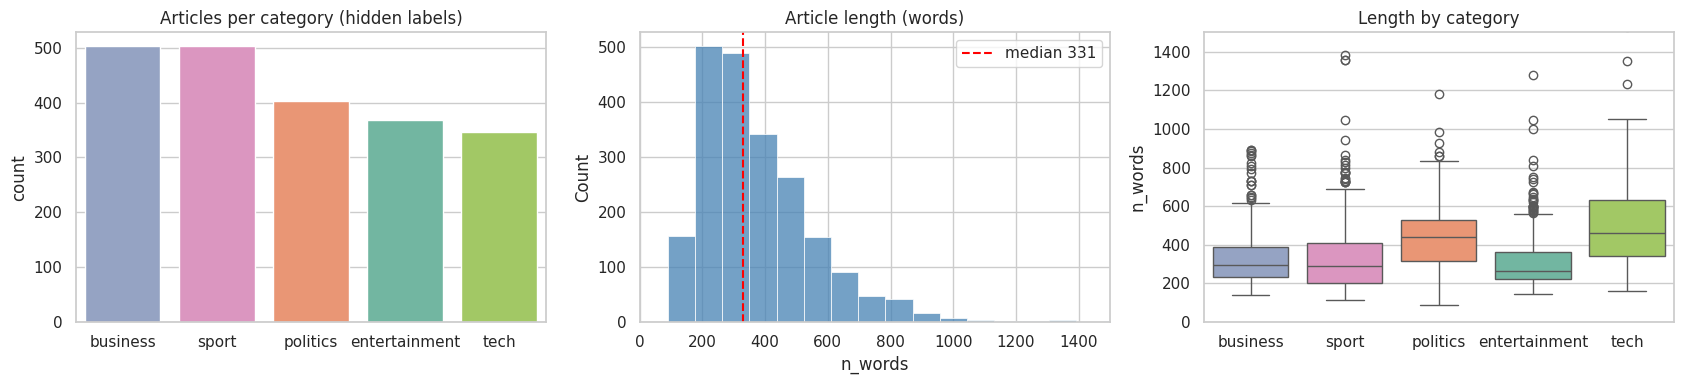

,count,mean,std,min,25%,50%,75%,max
n_words,2125.0,384.1,241.5,89.0,245.0,331.0,471.0,4432.0
n_sentences,2125.0,20.8,13.4,5.0,14.0,18.0,25.0,262.0


In [4]:
news["n_words"] = news["text"].str.split().str.len()
news["n_sentences"] = news["text"].str.count(r"[.!?]+")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
order = news["category"].value_counts().index
sns.countplot(data=news, x="category", order=order, hue="category", palette="Set2", legend=False, ax=axes[0])
axes[0].set(title="Articles per category (hidden labels)", xlabel="")
sns.histplot(news["n_words"], bins=50, ax=axes[1], color="steelblue")
axes[1].axvline(news["n_words"].median(), c="red", ls="--", label=f"median {news['n_words'].median():.0f}")
axes[1].set(title="Article length (words)", xlim=(0, 1500)); axes[1].legend()
sns.boxplot(data=news, x="category", y="n_words", order=order, hue="category", palette="Set2", legend=False, ax=axes[2])
axes[2].set(title="Length by category", ylim=(0, 1500), xlabel="")
plt.tight_layout()
save_fig("01_eda_overview")
plt.show()

news[["n_words", "n_sentences"]].describe().round(1).T

**Observations**
* The five categories are **roughly balanced** (each ~17–23%), so no single topic dominates the clustering.
* Articles are long (median 331 words, mean 384) with a long right tail — the longest has 4,432 words. After removing the archive's duplicate copies (the download contains every file twice, plus ~100 duplicate articles in the original corpus), **2,125 unique articles** remain. This matters for transformer models, which truncate long inputs (section 6).
* Lengths differ by category (tech and politics are longer, sport and business shorter), which is a reason to **L2-normalise** document vectors so long articles do not dominate distances.

In [5]:
# Most frequent raw words, before any cleaning: dominated by stop-words
raw_counts = Counter(w.lower() for t in news["text"] for w in re.findall(r"[A-Za-z']+", t))
pd.DataFrame(raw_counts.most_common(15), columns=["word", "count"]).set_index("word").T

word,the,to,of,and,a,in,for,is,that,on,said,it,was,he,be
count,50347,23932,19041,17742,17560,16992,8554,8173,7609,7315,6922,6710,5791,5552,5513


The raw top words ("the", "to", "of", "and", "a", "in"…) say nothing about topics — this shows why pre-processing is needed.

## 3. Text pre-processing
Each step below is applied in order:

| Step | What it does | Why |
|---|---|---|
| Lowercasing | "Market" → "market" | the same word should be one feature |
| Removing punctuation, digits & special characters | "£1.2bn," → " bn " | symbols and numbers rarely indicate a topic |
| Tokenisation | text → list of words (NLTK `word_tokenize`) | the unit of analysis is the word |
| Stop-word removal | drop "the", "said", "would", … | very common words carry no topic information |
| Lemmatisation (POS-aware) | "companies" → "company", "rising" → "rise" | merges inflected forms into one dictionary word |

We use **lemmatisation** rather than stemming because it returns real words (easier to interpret in the cluster key terms); a comparison with the Porter stemmer is shown below. "said", "mr", "also", "would", "year"… are added to the stop-word list because they appear in almost every news article.

In [6]:
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()
STOP_WORDS = set(stopwords.words("english")) | {
    "said", "say", "says", "mr", "mrs", "ms", "also", "would", "could", "one", "two", "new",
    "year", "years", "us", "told", "get", "make", "go", "bn", "m", "bbc"}


def to_wordnet_pos(tag: str):
    """Map a Penn Treebank POS tag to the WordNet POS used by the lemmatiser."""
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)


def clean_text(text: str) -> str:
    text = text.lower()                                     # 1. lowercase
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)                   # 2. remove punctuation, digits, symbols
    return re.sub(r"\s+", " ", text).strip()


def preprocess(text: str, return_steps: bool = False):
    cleaned = clean_text(text)
    tokens = word_tokenize(cleaned)                                          # 3. tokenise
    no_stop = [t for t in tokens if t not in STOP_WORDS and len(t) > 2]      # 4. stop-words
    lemmas = [lemmatizer.lemmatize(w, to_wordnet_pos(tag))                   # 5. lemmatise
              for w, tag in nltk.pos_tag(no_stop)]
    lemmas = [l for l in lemmas if l not in STOP_WORDS]
    if return_steps:
        return {"original": text, "lowercased + cleaned": cleaned, "tokens": tokens,
                "stop-words removed": no_stop, "lemmatised": lemmas}
    return " ".join(lemmas)

### 3.1 Worked example — every step on one sentence

In [7]:
example = "The companies' shares were rising sharply on Monday, after the £1.2bn deal was announced by the BBC's analysts!"
for step, value in preprocess(example, return_steps=True).items():
    print(f"{step:>22}: {value}")

              original: The companies' shares were rising sharply on Monday, after the £1.2bn deal was announced by the BBC's analysts!
  lowercased + cleaned: the companies shares were rising sharply on monday after the bn deal was announced by the bbc s analysts
                tokens: ['the', 'companies', 'shares', 'were', 'rising', 'sharply', 'on', 'monday', 'after', 'the', 'bn', 'deal', 'was', 'announced', 'by', 'the', 'bbc', 's', 'analysts']
    stop-words removed: ['companies', 'shares', 'rising', 'sharply', 'monday', 'deal', 'announced', 'analysts']
            lemmatised: ['company', 'share', 'rise', 'sharply', 'monday', 'deal', 'announce', 'analyst']


### 3.2 Stemming vs lemmatisation

In [8]:
words = ["studies", "studying", "companies", "running", "better", "elections", "economic", "economy", "played"]
pd.DataFrame({"word": words,
              "Porter stem": [stemmer.stem(w) for w in words],
              "Lemma (verb)": [lemmatizer.lemmatize(w, wordnet.VERB) for w in words],
              "Lemma (noun)": [lemmatizer.lemmatize(w) for w in words]}).set_index("word").T

word,studies,studying,companies,running,better,elections,economic,economy,played
Porter stem,studi,studi,compani,run,better,elect,econom,economi,play
Lemma (verb),study,study,company,run,better,elections,economic,economy,play
Lemma (noun),study,studying,company,running,better,election,economic,economy,played


The stemmer is fast but produces non-words ("compani", "studi", "econom"), and it merges *economic/economy* aggressively. Lemmatisation keeps readable words, which makes the cluster key terms easier to interpret, so we use it.

### 3.3 Apply to the whole corpus

In [9]:
news["clean"] = news["text"].apply(preprocess)
news["n_tokens_clean"] = news["clean"].str.split().str.len()
print(f"Average length: {news['n_words'].mean():.0f} words before -> {news['n_tokens_clean'].mean():.0f} tokens after pre-processing")
news[["title", "clean"]].head(3)

Average length: 384 words before -> 198 tokens after pre-processing


,title,clean
0,Rocker Doherty in on-stage fight,rocker doherty stage fight rock singer pete do...
1,BBC denies Blackadder TV comeback,denies blackadder comeback plan pipeline serie...
2,TV station refuses adoption show,station refuse adoption show station refuse sh...


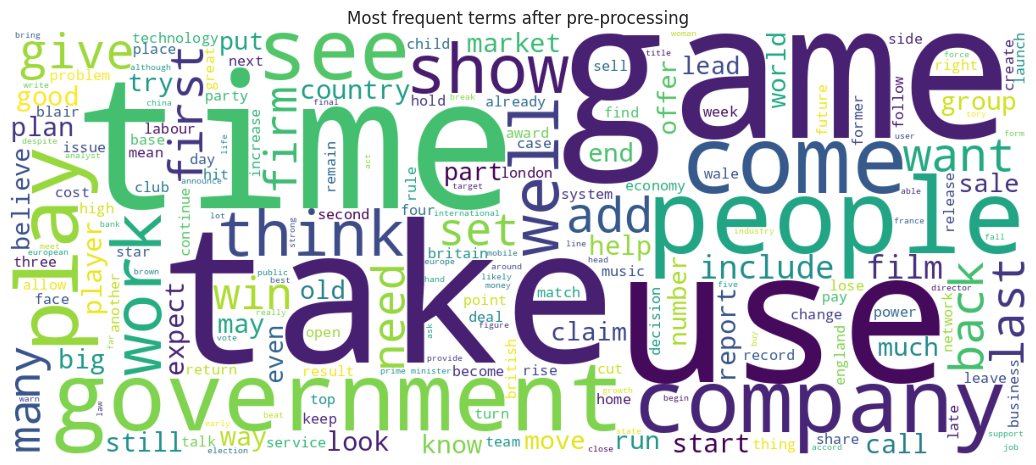

In [10]:
from wordcloud import WordCloud

wc = WordCloud(width=1200, height=500, background_color="white", colormap="viridis", random_state=SEED)
plt.figure(figsize=(14, 5.5))
plt.imshow(wc.generate(" ".join(news["clean"])))
plt.axis("off")
plt.title("Most frequent terms after pre-processing")
save_fig("02_wordcloud_corpus")
plt.show()

## 4. Feature extraction with TF-IDF

**TF-IDF** scores a term *t* in document *d* as

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \log\frac{1 + N}{1 + \text{df}(t)} + 1$$

* **TF (term frequency)** — how often *t* appears in *d* (we use sub-linear `1 + log(tf)`, so a word repeated 20 times does not count 20× more than once).
* **IDF (inverse document frequency)** — words that appear in many documents ("people", "time") get a low weight; words concentrated in a few documents ("striker", "broadband", "tory") get a high weight.

The result is a vector per document in which the **most distinctive words have the largest values**, which is exactly what is needed to separate topics. Each vector is L2-normalised, so the dot product between two documents is their **cosine similarity**.

**Settings:** unigrams + bigrams (captures phrases such as "prime minister", "interest rate"); terms in fewer than 5 documents (typos, rare names) or in more than 70% of documents (generic words) are dropped; vocabulary capped at 5,000 features.

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.7, max_features=5000, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(news["clean"])
terms = np.array(tfidf.get_feature_names_out())
sparsity = 1 - X_tfidf.nnz / np.prod(X_tfidf.shape)
print(f"TF-IDF matrix: {X_tfidf.shape[0]} documents x {X_tfidf.shape[1]} terms  (sparsity {sparsity:.1%})")

TF-IDF matrix: 2125 documents x 5000 terms  (sparsity 97.5%)


### 4.1 Key terms
Overall key terms are the terms with the highest **average TF-IDF** over the corpus. We also show the key terms of each (hidden) category, to verify that TF-IDF captures topic-specific vocabulary.

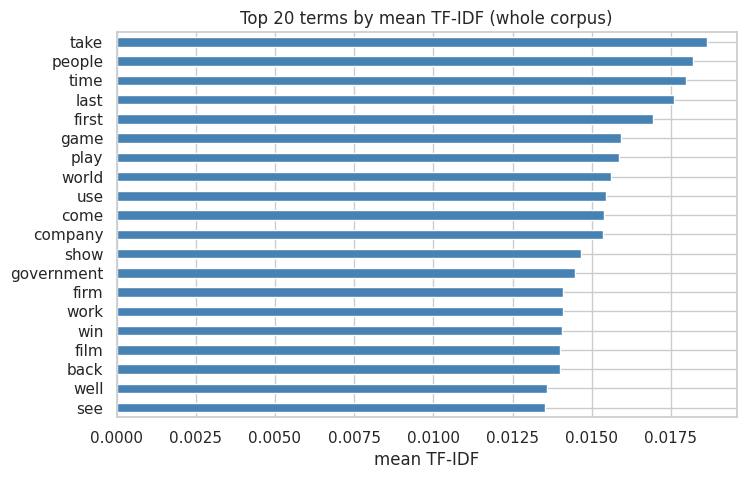

,business,entertainment,politics,sport,tech
0,company,film,labour,game,use
1,firm,star,election,win,technology
2,market,award,party,play,people
3,rise,show,government,player,user
4,share,best,tory,match,computer
5,growth,music,minister,team,mobile
6,bank,actor,blair,cup,software
7,economy,include,plan,champion,phone
8,price,band,people,coach,service
9,sale,singer,leader,injury,net


In [12]:
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_overall = pd.Series(mean_tfidf, index=terms).nlargest(20)

fig, ax = plt.subplots(figsize=(8, 5))
top_overall.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(title="Top 20 terms by mean TF-IDF (whole corpus)", xlabel="mean TF-IDF")
save_fig("03_top_tfidf_terms")
plt.show()

category_terms = {}
for cat in CATEGORIES:
    mask = (news["category"] == cat).to_numpy()
    scores = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    category_terms[cat] = terms[np.argsort(-scores)[:10]]
pd.DataFrame(category_terms)

In [13]:
# One document: which words does TF-IDF consider most important?
doc_id = 0
row = X_tfidf[doc_id].toarray().ravel()
print("Title:", news.loc[doc_id, "title"], f"[{news.loc[doc_id, 'category']}]")
pd.Series(row, index=terms).nlargest(10).round(3).to_frame("tf-idf weight").T

Title: Rocker Doherty in on-stage fight [entertainment]


,doherty,guitarist,bail,singer,gig,stage,fan,gmt,condition,monday
tf-idf weight,0.313,0.219,0.215,0.171,0.164,0.154,0.132,0.13,0.129,0.127


The per-category key terms are clearly topical (e.g. *game, win, player* for sport; *government, election, labour* for politics; *film, award, music* for entertainment; *company, market, growth* for business; *technology, mobile, software* for tech). TF-IDF therefore contains enough signal for clustering.

## 5. Document clustering with K-Means (TF-IDF)

**K-Means** places *K* centroids and repeatedly (1) assigns each document to the nearest centroid and (2) moves each centroid to the mean of its documents, minimising the within-cluster sum of squared distances (**inertia**). Because the TF-IDF rows are L2-normalised, Euclidean distance is equivalent to cosine distance. We use `k-means++` initialisation and 10 restarts to avoid poor local minima.

### 5.1 Choosing K — Elbow method and Silhouette score
* **Elbow:** inertia always falls as K grows; the "elbow" where the improvement slows suggests a natural K.
* **Silhouette** (−1 … 1): how much closer each document is to its own cluster than to the next nearest one (cosine distance). Higher is better.

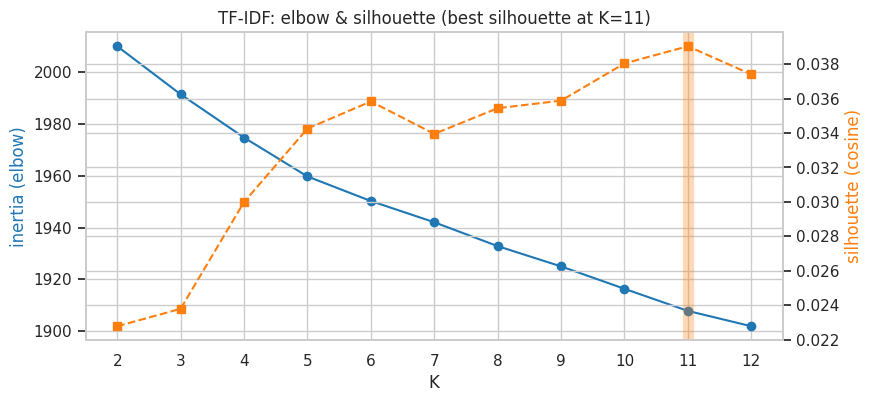

K,2,3,4,5,6,7,8,9,10,11,12
inertia,2010.0436,1991.4706,1974.7657,1959.7276,1950.2429,1942.0267,1932.8092,1924.9700,1916.3143,1907.7731,1901.8440
silhouette,0.0228,0.0238,0.0300,0.0343,0.0358,0.0339,0.0354,0.0359,0.0380,0.0390,0.0374


In [14]:
K_RANGE = range(2, 13)


def scan_k(X, metric="cosine"):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        rows.append({"K": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X, km.labels_, metric=metric, random_state=SEED)})
    return pd.DataFrame(rows).set_index("K")


def plot_k_scan(scan, title, name):
    fig, ax1 = plt.subplots(figsize=(9, 4))
    ax1.plot(scan.index, scan["inertia"], "o-", c="tab:blue")
    ax1.set_xlabel("K"); ax1.set_ylabel("inertia (elbow)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(scan.index, scan["silhouette"], "s--", c="tab:orange")
    ax2.set_ylabel("silhouette (cosine)", color="tab:orange")
    best = scan["silhouette"].idxmax()
    ax2.axvline(best, c="tab:orange", alpha=0.3, lw=8)
    ax1.set_title(f"{title}: elbow & silhouette (best silhouette at K={best})")
    ax1.set_xticks(list(scan.index))
    save_fig(name)
    plt.show()


scan_tfidf = scan_k(X_tfidf)
plot_k_scan(scan_tfidf, "TF-IDF", "04_k_selection_tfidf")
scan_tfidf.round(4).T

**Choosing K.** Silhouette values on sparse, high-dimensional TF-IDF data are typically small (≈ 0.01–0.03) because all documents are fairly far apart — the *relative* peak is what matters. On text, the inertia curve is often smooth, so the elbow is only a rough guide.

**Decision rule (fixed before looking at the true labels):** an editor organising an archive needs a handful of top-level sections, so we search **K between 3 and 8** and take the **silhouette peak** in that range; the elbow is reported as a cross-check. The true number of sections (5) is *not* used to choose K — the external metrics in section 7 then tell us whether the data-driven choice was sensible.

In [15]:
inertia = scan_tfidf["inertia"].to_numpy()
# Elbow = point of maximum curvature (largest second difference of inertia)
K_ELBOW = int(list(K_RANGE)[1:-1][np.argmax(inertia[:-2] - 2 * inertia[1:-1] + inertia[2:])])
K_SIL = int(scan_tfidf.loc[3:8, "silhouette"].idxmax())
K = K_SIL
print(f"Elbow (max curvature): K={K_ELBOW} | silhouette peak in 3..8: K={K_SIL}  ->  chosen K = {K}")

Elbow (max curvature): K=5 | silhouette peak in 3..8: K=6  ->  chosen K = 6


### 5.2 Final K-Means model and cluster interpretation
The **highest-weighted terms of each centroid** describe what the cluster is about. We give every cluster a human-readable name from its key terms.

In [16]:
km_tfidf = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_tfidf)
news["cluster_tfidf"] = km_tfidf.labels_

centroid_terms = {}
for c in range(K):
    top = terms[np.argsort(-km_tfidf.cluster_centers_[c])[:12]]
    centroid_terms[f"cluster {c} (n={np.sum(km_tfidf.labels_ == c)})"] = top
pd.DataFrame(centroid_terms)

,cluster 0 (n=385),cluster 1 (n=358),cluster 2 (n=372),cluster 3 (n=511),cluster 4 (n=135),cluster 5 (n=364)
0,labour,use,win,company,england,film
1,election,people,play,market,rugby,star
2,party,technology,game,firm,six nation,award
3,government,user,champion,share,ireland,best
4,tory,computer,player,rise,nation,show
5,blair,mobile,final,growth,game,actor
6,minister,phone,match,bank,coach,include
7,plan,service,club,economy,six,music
8,people,software,cup,price,wale,band
9,leader,digital,team,sale,side,oscar


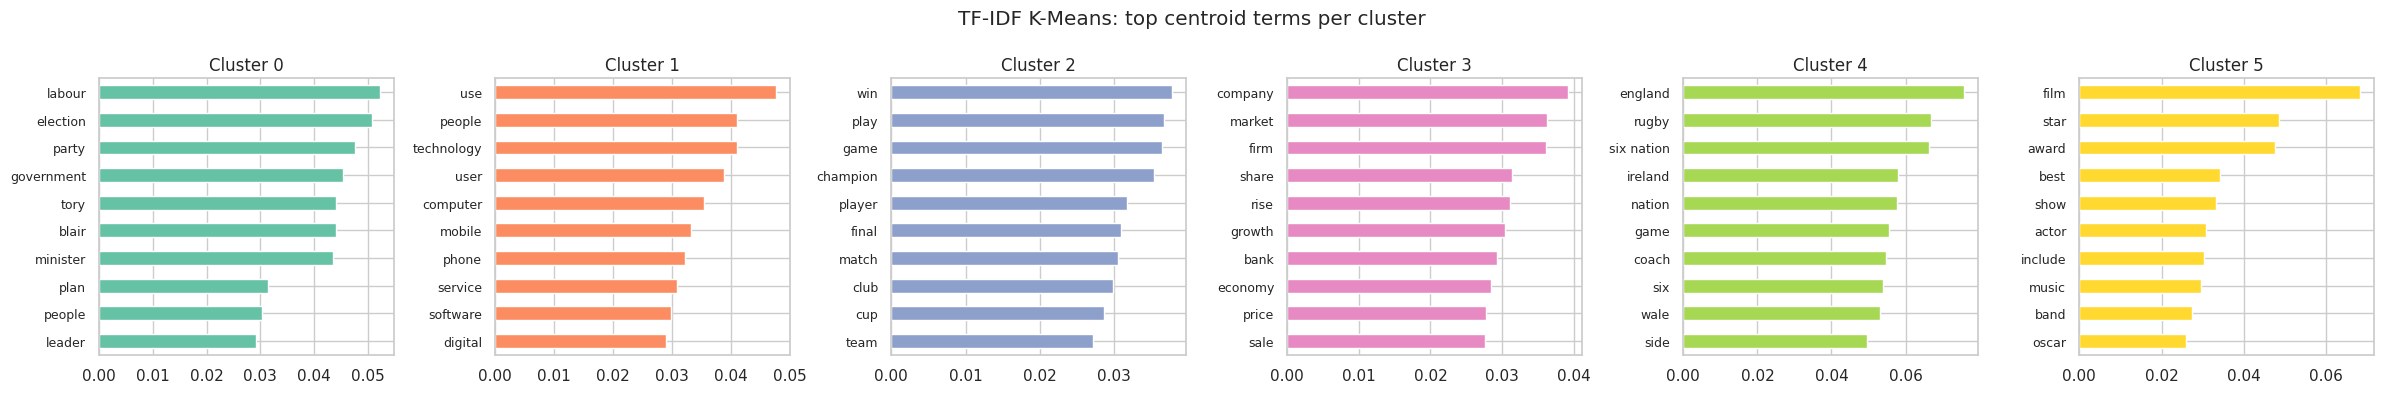

In [17]:
fig, axes = plt.subplots(1, K, figsize=(4 * K, 4))
for c, ax in enumerate(np.atleast_1d(axes)):
    weights = pd.Series(km_tfidf.cluster_centers_[c], index=terms).nlargest(10).sort_values()
    weights.plot.barh(ax=ax, color=sns.color_palette("Set2")[c % 8])
    ax.set_title(f"Cluster {c}")
    ax.tick_params(axis="y", labelsize=9)
plt.suptitle("TF-IDF K-Means: top centroid terms per cluster")
plt.tight_layout()
save_fig("05_cluster_top_terms_tfidf")
plt.show()

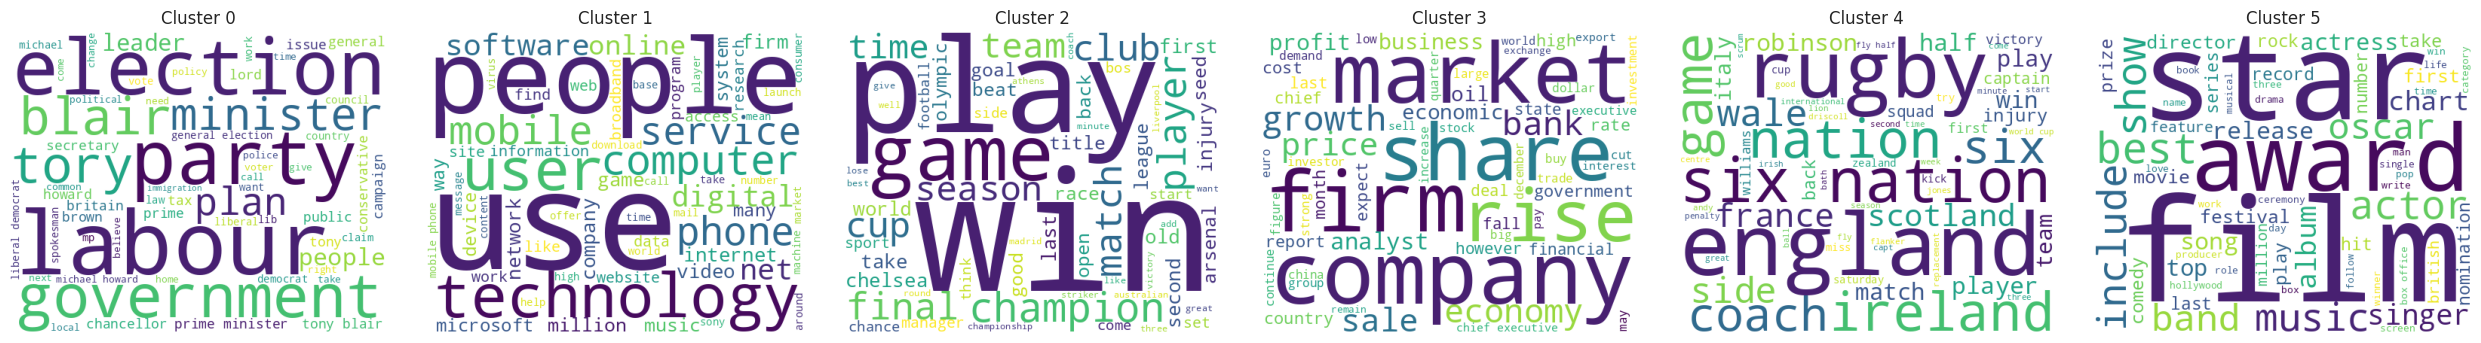

In [18]:
fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 3.4))
for c, ax in enumerate(np.atleast_1d(axes)):
    freqs = dict(pd.Series(km_tfidf.cluster_centers_[c], index=terms).nlargest(60))
    ax.imshow(WordCloud(width=500, height=400, background_color="white", random_state=SEED)
              .generate_from_frequencies(freqs))
    ax.set_title(f"Cluster {c}")
    ax.axis("off")
plt.tight_layout()
save_fig("06_cluster_wordclouds_tfidf")
plt.show()

### 5.3 Do the clusters match the hidden editorial sections?
The cross-tabulation below compares discovered clusters (rows) with the true categories (columns). Each cluster is labelled with its **majority category**.

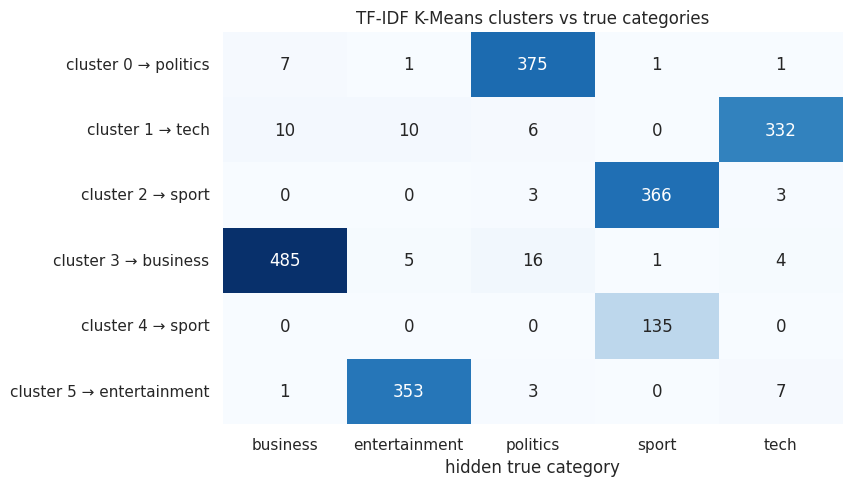

category,business,entertainment,politics,sport,tech
cluster 0 → politics,7,1,375,1,1
cluster 1 → tech,10,10,6,0,332
cluster 2 → sport,0,0,3,366,3
cluster 3 → business,485,5,16,1,4
cluster 4 → sport,0,0,0,135,0
cluster 5 → entertainment,1,353,3,0,7


In [19]:
def crosstab_plot(labels, title, name):
    ct = pd.crosstab(labels, news["category"])
    ct.index = [f"cluster {i} → {ct.loc[i].idxmax()}" for i in ct.index]
    plt.figure(figsize=(8, 0.6 * len(ct) + 1.5))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(title); plt.ylabel(""); plt.xlabel("hidden true category")
    save_fig(name)
    plt.show()
    return ct


crosstab_plot(news["cluster_tfidf"], "TF-IDF K-Means clusters vs true categories", "07_crosstab_tfidf")

### 5.4 Visualising the clusters in 2-D
TF-IDF has 5,000 dimensions, so we first reduce to 50 dimensions with **Truncated SVD (LSA)** and then to 2-D with **t-SNE**, which preserves local neighbourhoods. Left: coloured by K-Means cluster; right: coloured by the true category.

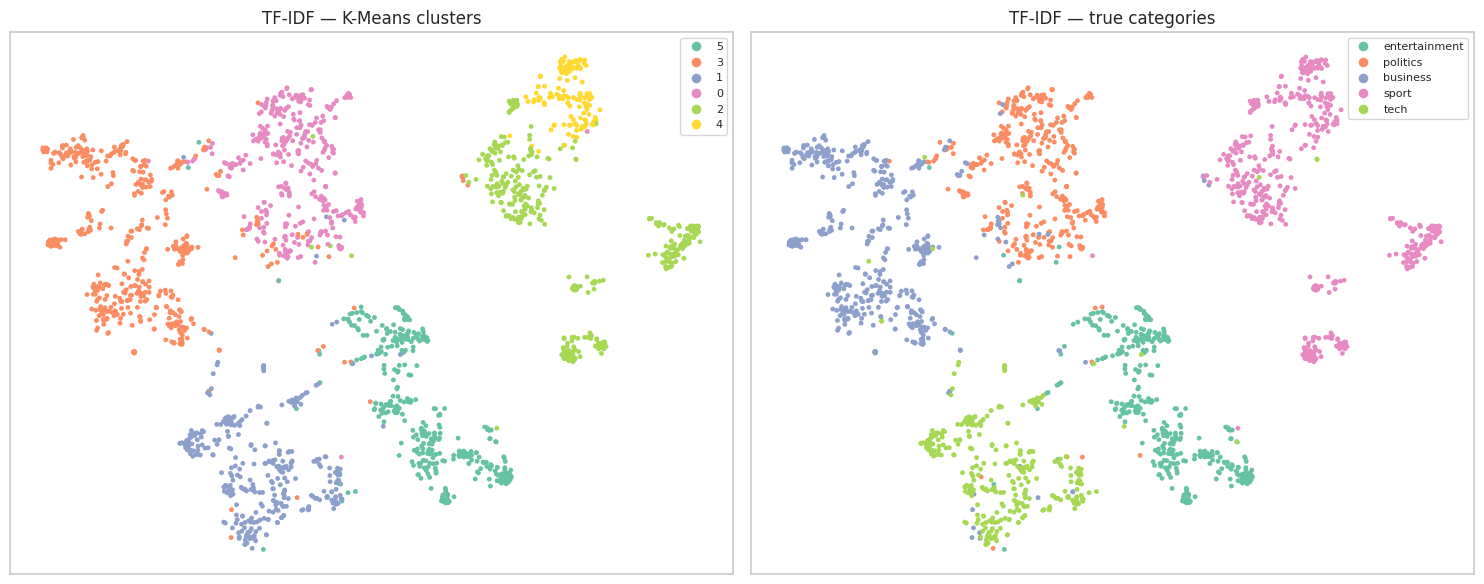

In [20]:
def tsne_2d(X):
    if X.shape[1] > 50:
        X = TruncatedSVD(n_components=50, random_state=SEED).fit_transform(X)
    return TSNE(n_components=2, perplexity=35, init="pca", metric="cosine", random_state=SEED).fit_transform(X)


def plot_2d(coords, cluster_labels, title, name):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, labels, sub in [(axes[0], cluster_labels, "K-Means clusters"), (axes[1], news["category"], "true categories")]:
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels, palette="Set2", s=12, ax=ax, linewidth=0)
        ax.set(title=f"{title} — {sub}", xticks=[], yticks=[])
        ax.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    save_fig(name)
    plt.show()


coords_tfidf = tsne_2d(X_tfidf)
plot_2d(coords_tfidf, news["cluster_tfidf"].astype(str), "TF-IDF", "08_tsne_tfidf")

## 6. Transformer-based embeddings
**Sentence-BERT** (Reimers & Gurevych, 2019) is a BERT-style transformer fine-tuned so that texts with similar *meaning* get nearby vectors, even when they share no words ("the striker scored" ≈ "the forward found the net"). Unlike TF-IDF, it:
* uses **context** (word order, synonyms, negation),
* produces **dense** vectors (384 / 768 dimensions instead of 5,000 sparse ones),
* needs **no stop-word removal or lemmatisation** — the raw text (title + body) is the input, because the model was trained on natural sentences.

We compare two pre-trained models:

| Model | Dimensions | Max tokens | Notes |
|---|---|---|---|
| `all-MiniLM-L6-v2` | 384 | 256 | 6 layers, very fast |
| `all-mpnet-base-v2` | 768 | 384 | 12 layers, higher quality, ~5× slower |

**Limitation:** both models truncate long input, so for long articles only the title and the first ~200–300 words are encoded. For news this is usually enough because the topic is stated early (inverted-pyramid writing style).

In [21]:
from sentence_transformers import SentenceTransformer
import torch, time

device = "cuda" if torch.cuda.is_available() else "cpu"
EMBEDDING_MODELS = {"MiniLM": "sentence-transformers/all-MiniLM-L6-v2",
                    "MPNet": "sentence-transformers/all-mpnet-base-v2"}
embeddings, encode_time = {}, {}
for short, model_name in EMBEDDING_MODELS.items():
    model = SentenceTransformer(model_name, device=device)
    start = time.time()
    embeddings[short] = model.encode(news["text"].tolist(), batch_size=32, show_progress_bar=True,
                                     normalize_embeddings=True)
    encode_time[short] = time.time() - start
    print(f"{short}: {embeddings[short].shape} in {encode_time[short]:.0f}s on {device}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (20 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/67 [00:00<?, ?it/s]

MPNet: (2125, 768) in 47s on cuda


### 6.1 Choosing K for the embeddings
The same Elbow + Silhouette procedure is repeated in each embedding space.

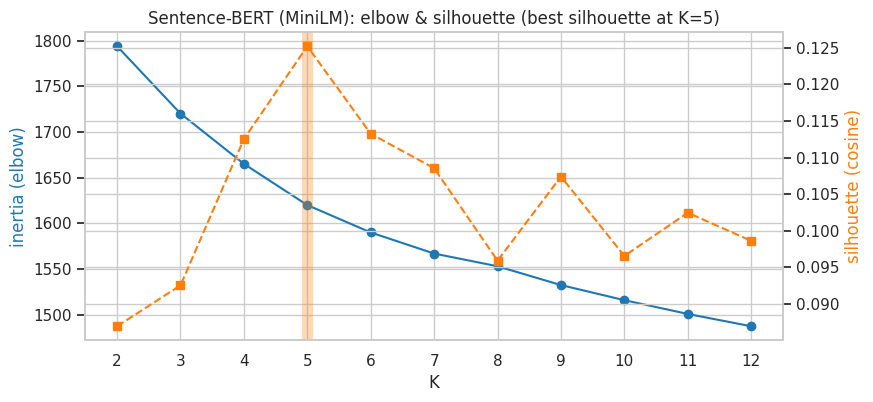

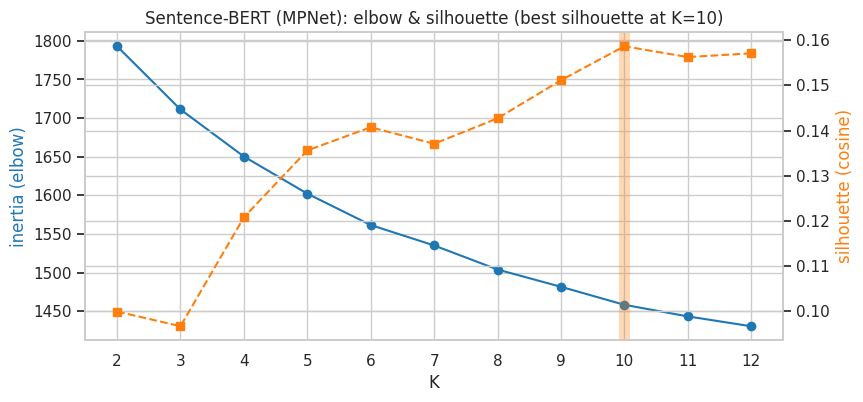

K,2,3,4,5,6,7,8,9,10,11,12
TF-IDF,0.0228,0.0238,0.0300,0.0343,0.0358,0.0339,0.0354,0.0359,0.0380,0.0390,0.0374
MiniLM,0.0869,0.0925,0.1125,0.1252,0.1132,0.1085,0.0959,0.1074,0.0965,0.1025,0.0986
MPNet,0.1000,0.0967,0.1208,0.1356,0.1407,0.1371,0.1427,0.1511,0.1586,0.1563,0.1571


In [22]:
scans_emb = {}
for short, E in embeddings.items():
    scans_emb[short] = scan_k(E)
    plot_k_scan(scans_emb[short], f"Sentence-BERT ({short})", f"09_k_selection_{short}")
pd.DataFrame({name: s["silhouette"] for name, s in {"TF-IDF": scan_tfidf, **scans_emb}.items()}).round(4).T

For a fair comparison all representations are clustered with the **same K** chosen above, so differences come from the representation, not from the number of clusters.

In [23]:
km_emb = {}
for short, E in embeddings.items():
    km_emb[short] = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(E)
    news[f"cluster_{short}"] = km_emb[short].labels_


def cluster_keywords(labels, top_n=10):
    """Interpret embedding clusters (which have no word-based centroids) by the mean TF-IDF of their documents."""
    out = {}
    for c in sorted(np.unique(labels)):
        scores = np.asarray(X_tfidf[labels == c].mean(axis=0)).ravel()
        out[f"cluster {c} (n={np.sum(labels == c)})"] = terms[np.argsort(-scores)[:top_n]]
    return pd.DataFrame(out)


cluster_keywords(news["cluster_MPNet"].to_numpy())

,cluster 0 (n=470),cluster 1 (n=325),cluster 2 (n=374),cluster 3 (n=358),cluster 4 (n=412),cluster 5 (n=186)
0,company,game,film,use,labour,champion
1,firm,player,star,technology,election,win
2,market,club,award,people,party,final
3,rise,england,best,user,government,world
4,share,play,show,computer,tory,olympic
5,growth,side,music,mobile,minister,open
6,bank,team,actor,phone,blair,seed
7,economy,cup,include,service,plan,race
8,sale,win,band,software,people,australian
9,price,match,singer,net,secretary,second


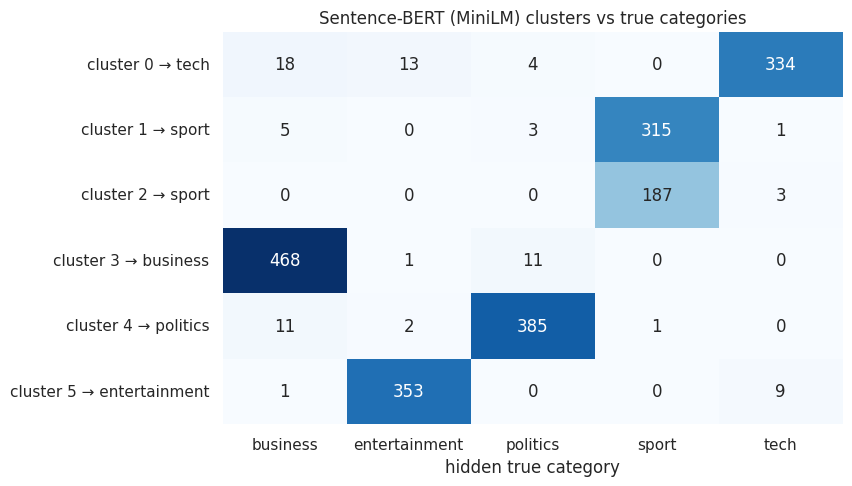

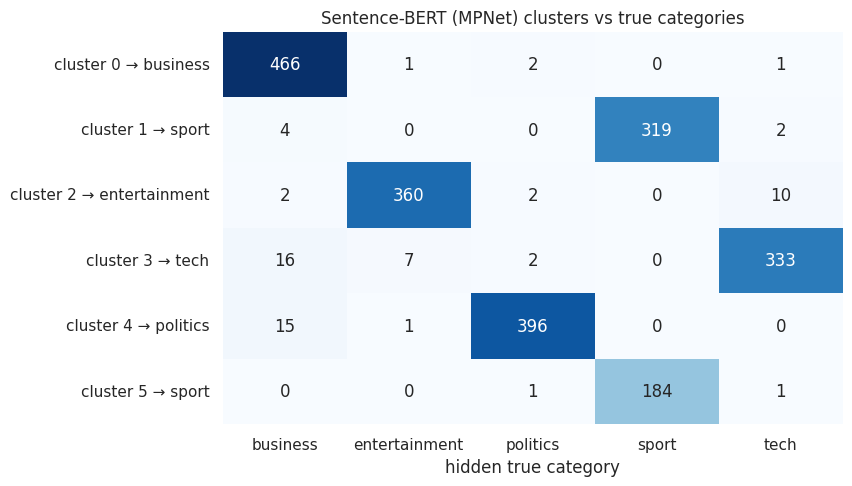

In [24]:
for short in embeddings:
    crosstab_plot(news[f"cluster_{short}"], f"Sentence-BERT ({short}) clusters vs true categories", f"10_crosstab_{short}")

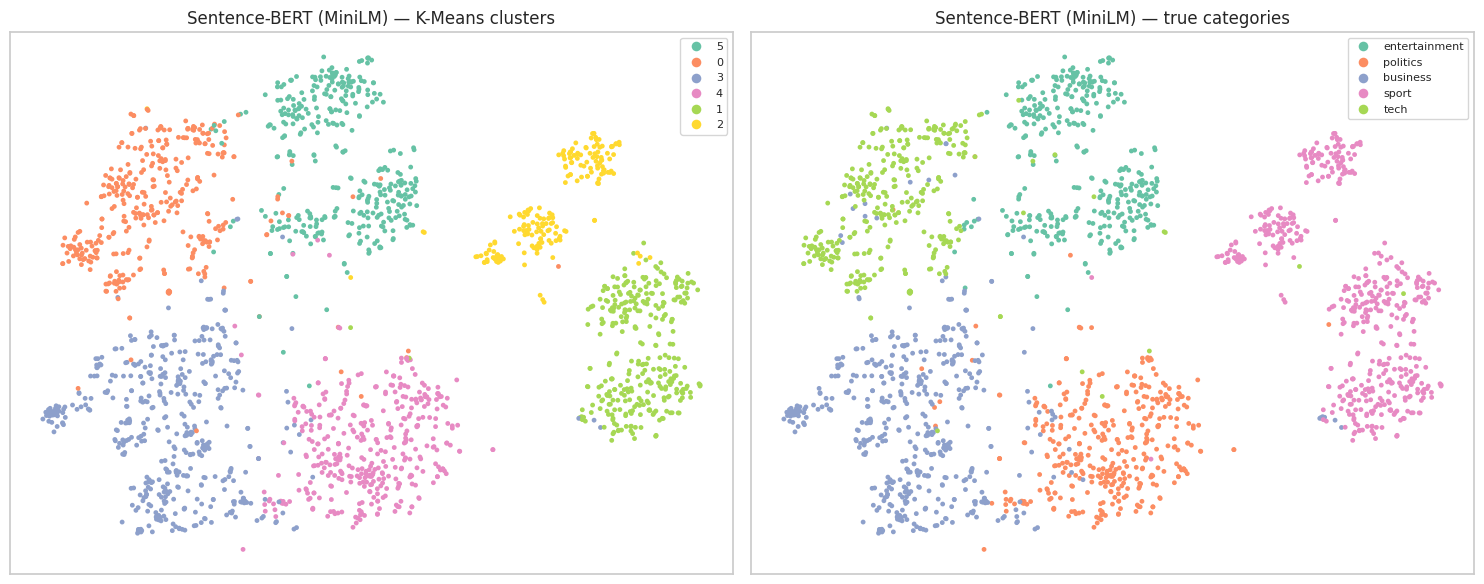

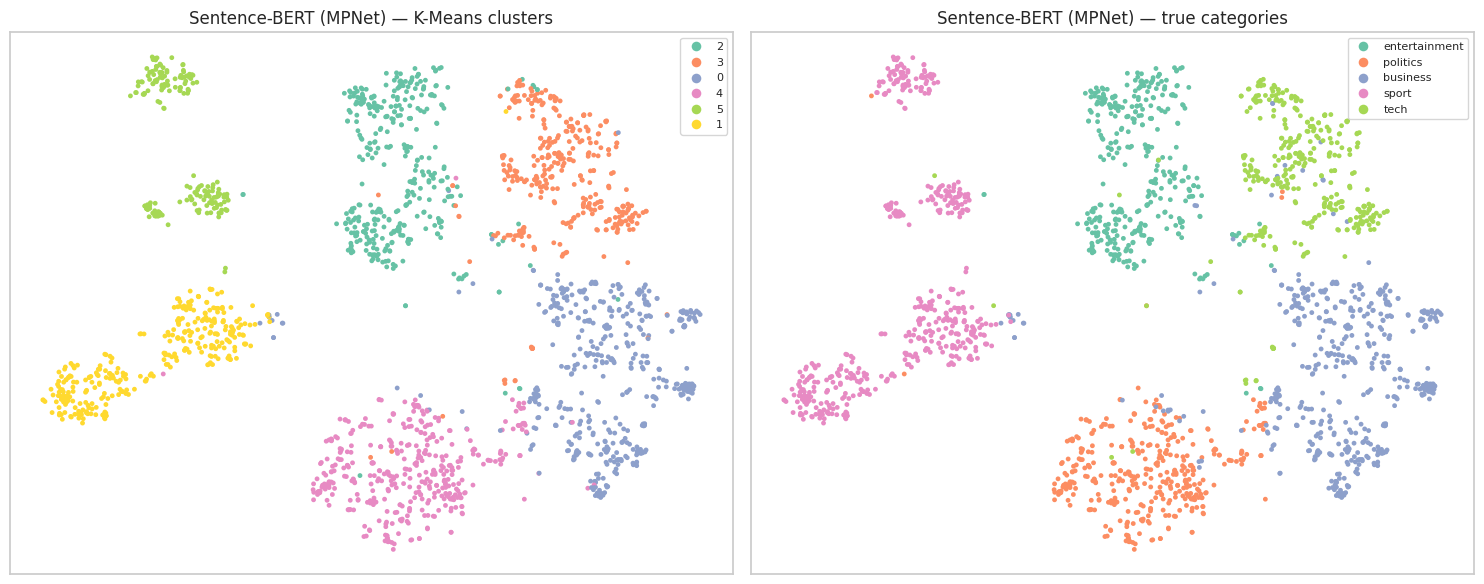

In [25]:
coords_emb = {short: tsne_2d(E) for short, E in embeddings.items()}
for short in embeddings:
    plot_2d(coords_emb[short], news[f"cluster_{short}"].astype(str), f"Sentence-BERT ({short})", f"11_tsne_{short}")

## 7. Measuring and comparing cluster quality

| Metric | Type | Range | Meaning |
|---|---|---|---|
| Silhouette (cosine) | internal | −1 … 1 ↑ | cohesion vs separation of clusters |
| Davies–Bouldin | internal | 0 … ∞ ↓ | average similarity of each cluster to its most similar cluster |
| Calinski–Harabasz | internal | 0 … ∞ ↑ | between-cluster vs within-cluster dispersion |
| Adjusted Rand Index (ARI) | external | −0.5 … 1 ↑ | agreement of pairs of documents with the true categories, corrected for chance |
| Normalised Mutual Information (NMI) | external | 0 … 1 ↑ | information shared between clusters and categories |
| V-measure | external | 0 … 1 ↑ | harmonic mean of homogeneity and completeness |
| Purity | external | 0 … 1 ↑ | share of documents in their cluster's majority category |
| Stability (mean ARI over 10 seeds) | robustness | 0 … 1 ↑ | do different random starts give the same clustering? |

**Important caveat:** internal metrics are computed *in each representation's own space*, so a silhouette of 0.02 in TF-IDF space and 0.08 in embedding space are **not directly comparable** (the geometry of sparse 5,000-D vectors and dense 384-D vectors is very different). The **external metrics** use the same reference (the editorial categories) for every method, so they are the fairest basis for comparison.

In [26]:
def purity(labels_true, labels_pred):
    cm = contingency_matrix(labels_true, labels_pred)
    return cm.max(axis=0).sum() / cm.sum()


def stability(X, k, seeds=range(10)):
    """Mean pairwise ARI between K-Means runs with different random seeds."""
    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X) for s in seeds]
    return np.mean([adjusted_rand_score(runs[i], runs[j]) for i in range(len(runs)) for j in range(i + 1, len(runs))])


def quality(X, labels, dense):
    Xd = X if dense else X.toarray()
    return {
        "Silhouette (cos) ↑": silhouette_score(X, labels, metric="cosine", random_state=SEED),
        "Davies–Bouldin ↓": davies_bouldin_score(Xd, labels),
        "Calinski–Harabasz ↑": calinski_harabasz_score(Xd, labels),
        "ARI ↑": adjusted_rand_score(news["category"], labels),
        "NMI ↑": normalized_mutual_info_score(news["category"], labels),
        "V-measure ↑": v_measure_score(news["category"], labels),
        "Purity ↑": purity(news["category"], labels),
        "Stability ↑": stability(X, K),
        "Dimensions": X.shape[1],
    }


quality_table = pd.DataFrame({
    "TF-IDF": quality(X_tfidf, news["cluster_tfidf"], dense=False),
    **{f"SBERT {s}": quality(E, news[f"cluster_{s}"], dense=True) for s, E in embeddings.items()},
}).T
quality_table.to_csv(FIG_DIR / "cluster_quality.csv")
quality_table.style.format("{:.3f}").highlight_max(
    subset=["ARI ↑", "NMI ↑", "V-measure ↑", "Purity ↑"], color="#c6efce")

,Silhouette (cos) ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,ARI ↑,NMI ↑,V-measure ↑,Purity ↑,Stability ↑,Dimensions
TF-IDF,0.033,6.780,18.105,0.841,0.846,0.846,0.963,0.688,5000.000
SBERT MiniLM,0.113,3.446,80.395,0.823,0.842,0.842,0.961,0.830,384.000
SBERT MPNet,0.141,3.199,89.767,0.840,0.860,0.860,0.968,0.779,768.000


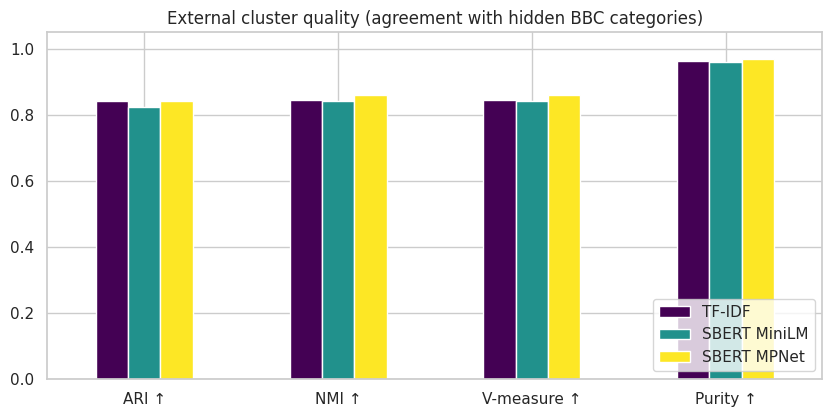

In [27]:
external = quality_table[["ARI ↑", "NMI ↑", "V-measure ↑", "Purity ↑"]]
ax = external.T.plot.bar(figsize=(10, 4.5), rot=0, colormap="viridis")
ax.set(title="External cluster quality (agreement with hidden BBC categories)", ylim=(0, 1.05))
ax.legend(loc="lower right")
save_fig("12_quality_comparison")
plt.show()

### 7.1 Where do the methods disagree?
Articles that TF-IDF and the best embedding model place in different (majority-mapped) categories reveal the strengths of each approach.

In [28]:
def majority_mapping(labels):
    ct = pd.crosstab(labels, news["category"])
    return labels.map(ct.idxmax(axis=1))


best_emb = external.drop(index="TF-IDF")["NMI ↑"].idxmax().replace("SBERT ", "")
news["topic_tfidf"] = majority_mapping(news["cluster_tfidf"])
news[f"topic_{best_emb}"] = majority_mapping(news[f"cluster_{best_emb}"])
disagree = news[news["topic_tfidf"] != news[f"topic_{best_emb}"]]
print(f"TF-IDF and SBERT-{best_emb} disagree on {len(disagree)} of {len(news)} articles "
      f"({len(disagree) / len(news):.1%}). Correct by category: TF-IDF "
      f"{(disagree['topic_tfidf'] == disagree['category']).sum()}, SBERT {(disagree[f'topic_{best_emb}'] == disagree['category']).sum()}")
disagree[["title", "category", "topic_tfidf", f"topic_{best_emb}"]].head(10)

TF-IDF and SBERT-MPNet disagree on 89 of 2125 articles (4.2%). Correct by category: TF-IDF 36, SBERT 48


,title,category,topic_tfidf,topic_MPNet
11,UK's National Gallery in the pink,entertainment,business,entertainment
40,UK 'world's biggest music buyer',entertainment,tech,entertainment
55,TV show unites Angolan families,entertainment,tech,entertainment
82,Musicians to tackle US red tape,entertainment,business,entertainment
109,Wal-Mart is sued over rude lyrics,entertainment,tech,entertainment
120,Row threatens Hendrix museum plan,entertainment,business,entertainment
150,Fears raised over ballet future,entertainment,tech,entertainment
183,Housewives lift Channel 4 ratings,entertainment,entertainment,tech
210,Download chart debut is delayed,entertainment,entertainment,tech
233,Wife Swap makers sue US 'copycat',entertainment,entertainment,business


In [29]:
# Automatically generated summary for the report
best_overall = external["NMI ↑"].idxmax()
print(f"- Chosen K = {K} (silhouette peak in 3..8, elbow K={K_ELBOW}); the corpus has 5 editorial sections.")
for name, r in quality_table.iterrows():
    print(f"- {name:12s}: ARI {r['ARI ↑']:.3f} | NMI {r['NMI ↑']:.3f} | purity {r['Purity ↑']:.3f} | "
          f"silhouette {r['Silhouette (cos) ↑']:.3f} | stability {r['Stability ↑']:.3f}")
print(f"- Best agreement with the true categories: {best_overall}")
print("- Encoding time: " + ", ".join(f"{k} {v:.0f}s" for k, v in encode_time.items()) + f" on {device}")

- Chosen K = 6 (silhouette peak in 3..8, elbow K=5); the corpus has 5 editorial sections.
- TF-IDF      : ARI 0.841 | NMI 0.846 | purity 0.963 | silhouette 0.033 | stability 0.688
- SBERT MiniLM: ARI 0.823 | NMI 0.842 | purity 0.961 | silhouette 0.113 | stability 0.830
- SBERT MPNet : ARI 0.840 | NMI 0.860 | purity 0.968 | silhouette 0.141 | stability 0.779
- Best agreement with the true categories: SBERT MPNet
- Encoding time: MiniLM 9s, MPNet 47s on cuda


## 8. Conclusions and recommendations

### 8.1 Results

| Representation | ARI | NMI | Purity | Silhouette (own space) | Stability | Encoding time (T4) |
|---|---|---|---|---|---|---|
| TF-IDF (5,000 terms) | **0.841** | 0.846 | 0.963 | 0.033 | 0.688 | < 1 s |
| Sentence-BERT MiniLM (384-D) | 0.823 | 0.842 | 0.961 | 0.113 | **0.830** | 9 s |
| Sentence-BERT MPNet (768-D) | 0.840 | **0.860** | **0.968** | **0.141** | 0.779 | 47 s |

### 8.2 Effectiveness of the approaches
* **Both representations recover the editorial structure without labels.** Purity is above 96% for all three: almost every cluster is dominated by a single BBC section.
* **The data-driven K was 6, not 5, and this is a meaningful finding.** The silhouette peak (K = 6) differed from the elbow (K = 5); in both cases the extra cluster comes from **sport**, the most internally diverse section. TF-IDF split off a **rugby / Six Nations** cluster (135 articles: *england, rugby, six nations, ireland, wales*), while MPNet split sport into **team sports** (*game, player, club, cup*) and **individual sports** (186 articles: *champion, olympic, seed, open, race* — tennis and athletics). The embedding split is more semantically sensible (it groups by the *type* of sport rather than by one tournament's vocabulary).
* **TF-IDF + K-Means** is transparent and cheap: each centroid is a list of weighted words, so clusters were named instantly (politics: *labour, election, party, tory, blair*; business: *company, market, firm, share*; tech: *technology, user, computer, mobile*; entertainment: *film, star, award, actor*). Its ARI is marginally the highest (0.841), but it is the **least stable** (0.69 mean ARI between random restarts) and has a very low silhouette (0.033), a consequence of sparse 5,000-dimensional vectors.
* **Sentence-BERT** gives tighter clusters (silhouette 0.11–0.14, 3–4× TF-IDF) and more stable ones (0.78–0.83), needs no linguistic pre-processing and groups by meaning. MPNet has the **best NMI and purity**. Costs: GPU encoding time (47 s for MPNet vs < 1 s for TF-IDF), no direct interpretability (TF-IDF terms were borrowed to name its clusters), and truncation of long articles to their first ~300 tokens.
* **The two methods agree on 95.8% of articles.** On the 89 articles where they disagree, MPNet is correct more often (48 vs 36), typically on stories that use another section's vocabulary (e.g. business stories about technology firms).
* **Measuring quality.** Internal metrics alone would have exaggerated the gap (silhouette 0.141 vs 0.033) because they are computed in different spaces; the external metrics against the hidden categories show the methods are actually very close (ARI 0.840 vs 0.841). Using both kinds of metric — plus stability — was essential for a fair comparison.

### 8.3 Recommendation for this dataset
* **Recommended: Sentence-BERT MPNet + K-Means**, with **TF-IDF top terms used to label the clusters** for humans. It has the best agreement with the editorial sections (NMI 0.860, purity 96.8%), more coherent and more stable clusters, and its sub-topics (team vs individual sport) are more useful for an archive.
* **Cheap alternative:** on a well-separated corpus like BBC News, **TF-IDF + K-Means performs almost as well** (ARI 0.841) at a tiny fraction of the cost and with full explainability — a good choice when there is no GPU or when editors must see *why* an article was grouped. Run it with several restarts because it is less stable.
* **Future work:** chunk long articles and average their embeddings to avoid truncation; try HDBSCAN or BERTopic, which do not require K and can expose sub-topics hierarchically (e.g. football / rugby / tennis within sport).